In [1]:
# read nc output from WAOM 10km run

import xarray as xr
import pandas as p
import numpy as np
import numpy.ma as ma
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import matplotlib as mpl
# mpl.use('Agg')
import matplotlib.pyplot as plt
import matplotlib.dates as dates
from matplotlib.ticker import NullFormatter
from matplotlib.colors import LinearSegmentedColormap   # for custom colormaps

import matplotlib.ticker as mticker
from cartopy.mpl.gridliner import LONGITUDE_FORMATTER, LATITUDE_FORMATTER

from datetime import datetime, timedelta

from netCDF4 import Dataset
from netCDF4 import num2date, date2num
from matplotlib.ticker import NullFormatter
from matplotlib.colors import LinearSegmentedColormap   # for custom colormaps

import gsw
import cmocean

import pyresample

from dask.distributed import Client
import logging
import warnings
warnings.filterwarnings('ignore')

In [2]:
client = Client()#threads_per_worker=1, memory_limit=0)#, silence_logs=logging.ERROR)
print(client)

<Client: 'tcp://127.0.0.1:36823' processes=7 threads=14, memory=510.00 GiB>


#### quick check on lon/lat for 2km setup - cropping data for Jeremy Shum (Monash Uni)

In [3]:
# read grid file for lon/lat coordinates
dg = xr.open_dataset("/g/data/gv90/fbd581/ROMS/waom2_frc/waom2extend_grd.nc")
angle_2km= dg.variables["angle"]
lat_rho_2km= dg.variables["lat_rho"]
lon_rho_2km = dg.variables["lon_rho"]


coordinates wanted:

150.3157477093938894,-68.9348667724699311 : 
154.6506086627791774,-67.3154670530012424 (EPSG:4326 - WGS 84 - Geographic)

lon_rho: 150:154E

lat_rho: -67:-69S

In [4]:
%%time

# Define your bounding box
lon_min, lon_max = 150, 154
lat_min, lat_max = -69, -67


# Apply mask using 2D lon/lat variables
mask = (
    (dg.lon_rho >= lon_min) & (dg.lon_rho <= lon_max) &
    (dg.lat_rho >= lat_min) & (dg.lat_rho <= lat_max)
)

# Apply the mask to the dataset
# subset = dg.where(mask, drop=True)


CPU times: user 41.2 ms, sys: 86.5 ms, total: 128 ms
Wall time: 115 ms


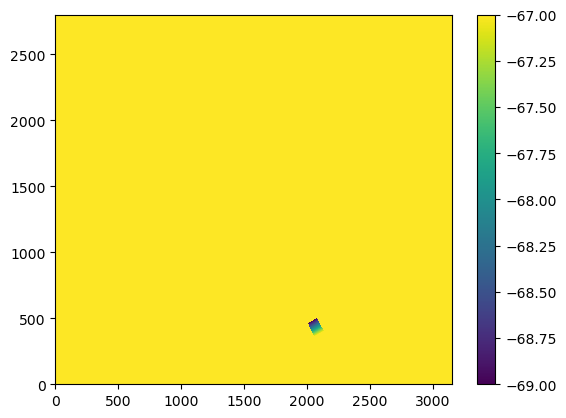

In [5]:
plt.pcolormesh(lat_rho_2km*mask)
plt.clim(-69,-67)
plt.colorbar()

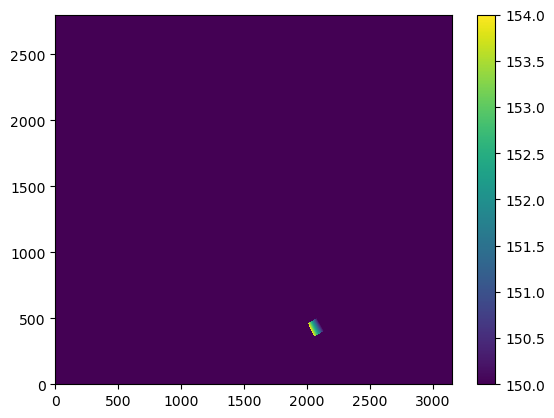

In [6]:
plt.pcolormesh(lon_rho_2km*mask)
plt.clim(150,154)
plt.colorbar()

In [22]:

# Load the ROMS grid file
gridfile = '/g/data/gv90/fbd581/ROMS/waom2_frc/waom2extend_grd.nc'
ds = xr.open_dataset(gridfile)

# Define the bounding box
lon_min, lon_max = 150, 154
lat_min, lat_max = -69, -67

# Create the mask based on the bounding box
mask = (
    (ds.lon_rho >= lon_min) & (ds.lon_rho <= lon_max) &
    (ds.lat_rho >= lat_min) & (ds.lat_rho <= lat_max))

# Convert the mask to integer type (1 for inside, 0 for outside)
mask = mask.astype(int)

# Create a new dataset for the mask
mask_ds = xr.Dataset({'mask': (['eta_rho', 'xi_rho'], mask.data),
                      'lon_rho': (['eta_rho', 'xi_rho'], ds.lon_rho.values),
                      'lat_rho': (['eta_rho', 'xi_rho'], ds.lat_rho.values)},
                     coords={
                         'eta_rho': (ds.eta_rho.values),
                         'xi_rho': (ds.xi_rho.values)})

# Save the mask to a NetCDF file
mask_ds.to_netcdf('/g/data/e14/fbd581/ROMS/OUTPUT/waom2extend_shflim_S_0.25Q/test_subsample/subset_mask.nc')
print("✅ Mask file 'subset_mask.nc' created successfully.")


✅ Mask file 'subset_mask.nc' created successfully.
